### Tarik dataset

In [325]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [326]:
columns = [
    'mpg', 'cylinders', 'displacement',
    'horsepower', 'weight', 'acceleration',
    'model_year', 'origin', 'car_name'
]

df = pd.read_csv(
    'auto-mpg.data',
    sep=r'\s+',
    names=columns,
    na_values='?'
)

### EDA

In [327]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [328]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
393,27.0,4,140.0,86.0,2790.0,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52.0,2130.0,24.6,82,2,vw pickup
395,32.0,4,135.0,84.0,2295.0,11.6,82,1,dodge rampage
396,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger
397,31.0,4,119.0,82.0,2720.0,19.4,82,1,chevy s-10


In [329]:
df.shape

(398, 9)

In [330]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB


In [331]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [332]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

In [333]:
df.duplicated().sum()

np.int64(0)

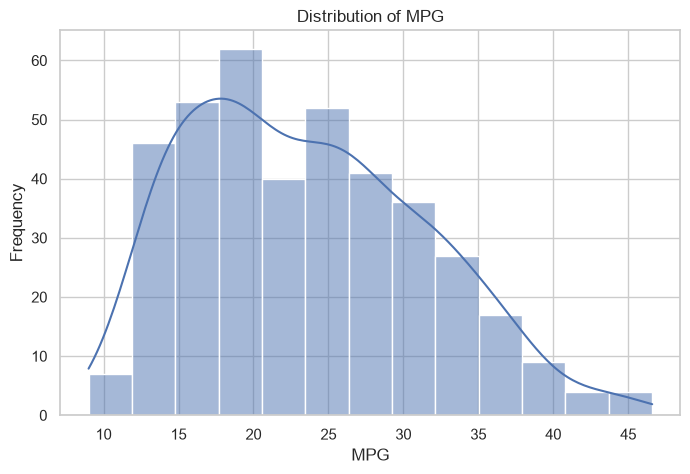

In [334]:
plt.figure(figsize=(8, 5))

sns.histplot(df['mpg'], kde=True)

plt.title('Distribution of MPG')
plt.xlabel('MPG')
plt.ylabel('Frequency')
plt.show()

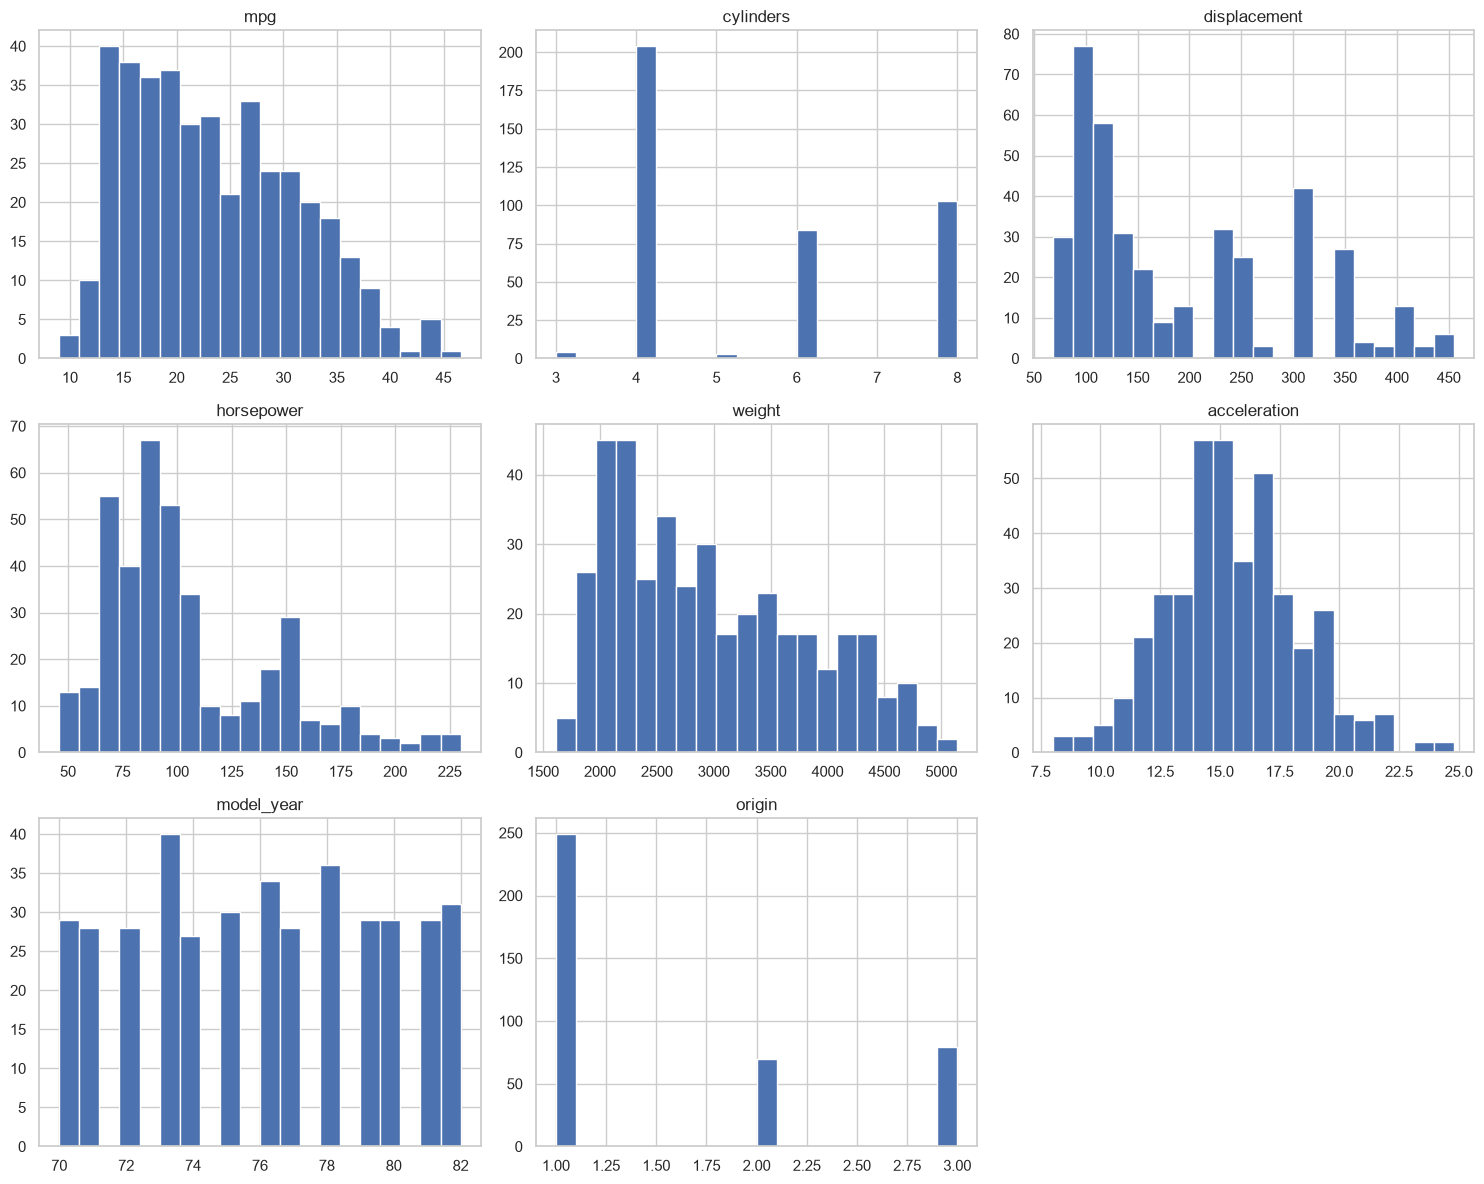

In [335]:
df.hist(figsize=(15, 12), bins=20)

plt.tight_layout()
plt.show()

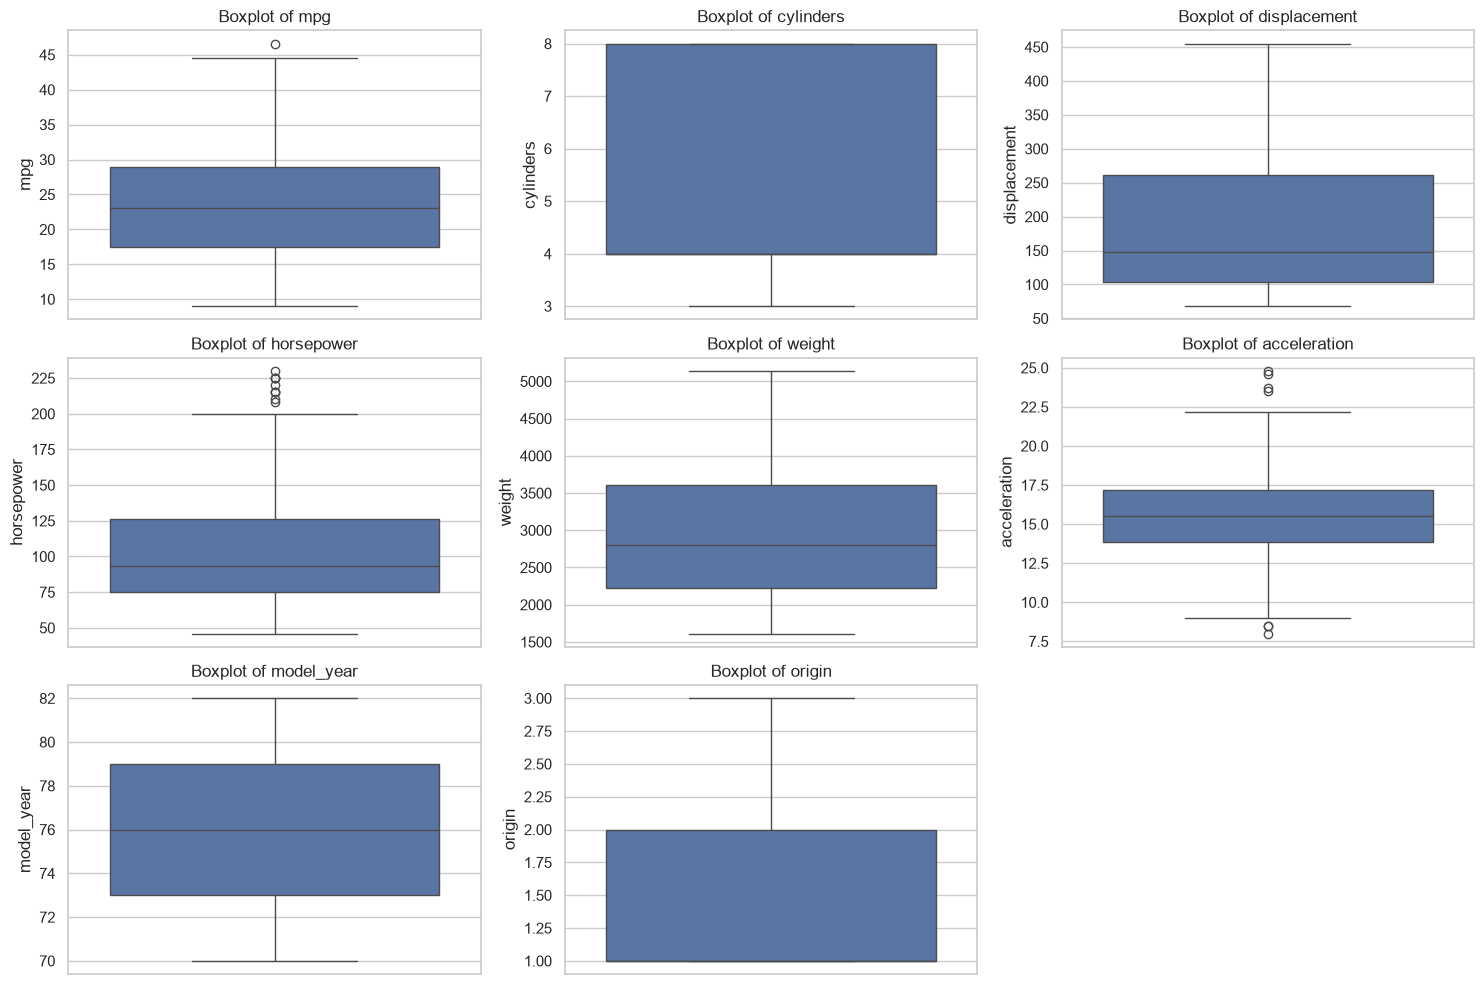

In [336]:
numerical_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

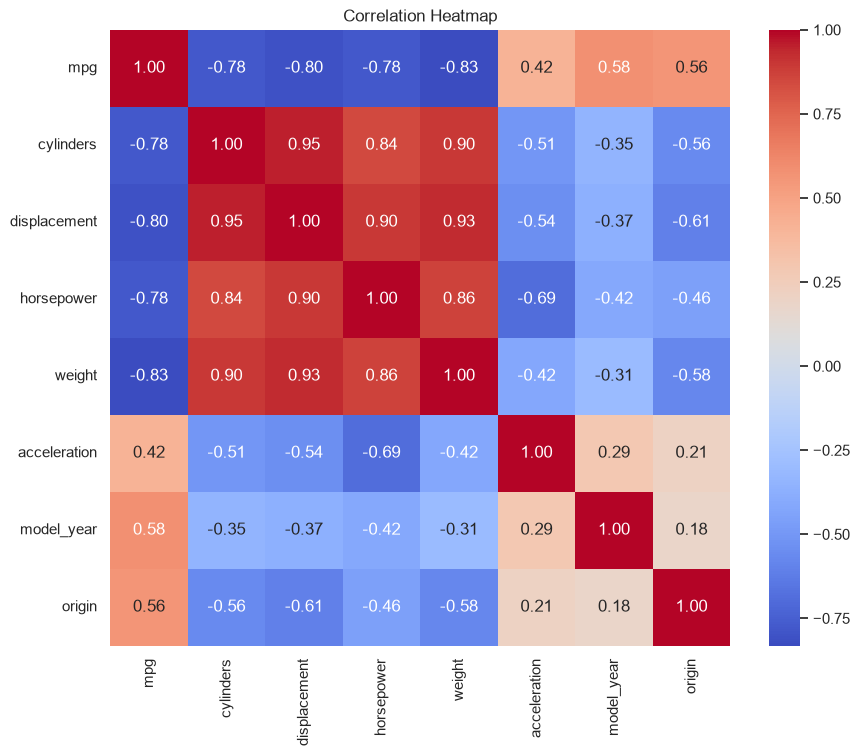

In [337]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

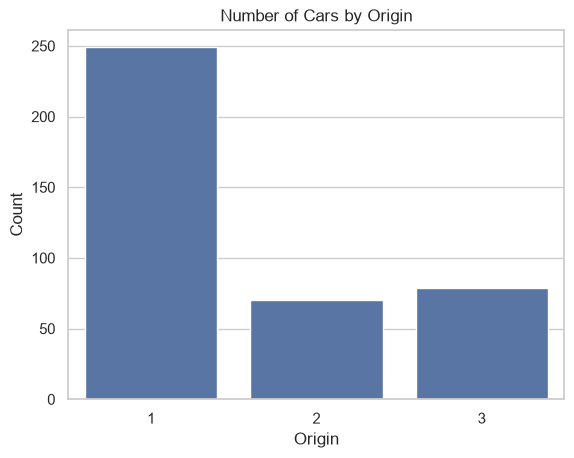

In [338]:
sns.countplot(data=df, x='origin')

plt.title('Number of Cars by Origin')
plt.xlabel('Origin')
plt.ylabel('Count')
plt.show()

Analisa:
- Distribusi data agak miring ke kanan
- Missing value hanya ada di horsepower sebesar 6 baris
- Fitur paling berkolerasi dengan mpg: weight (-0.83), displacement (-0.80), cylinder (-0.78), dan horsepower (-0.78). Makin berat dan makin besar mesinnya, MPGnya makin tinggi aliasmakin boros.
- Outlier ringan di horsepower dan acceleration

### Preprocessing

In [339]:
df_prep = df.copy()

In [340]:
df_prep.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

In [341]:
df_prep['horsepower'] = df_prep['horsepower'].fillna(df_prep['horsepower'].median())

In [342]:
df_prep = df_prep.drop(columns=['car_name'])

One-hot encoding

In [343]:
df_prep = pd.get_dummies(
    df_prep,
    columns=['origin'],
    prefix='origin',
    dtype=int
)

Pisah fitur dan target

In [344]:
X = df_prep.drop(columns=['mpg'])
y = df_prep['mpg']

Train-test split

In [345]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Fitur scaling

In [346]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train_scaled.shape)
print("X_test:", X_test_scaled.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (318, 9)
X_test: (80, 9)
y_train: (318,)
y_test: (80,)


### Modeling

In [347]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [348]:
models = {
    'Linear Regression': LinearRegression(),
    'Lasso (L1)': Lasso(alpha=0.5, max_iter=10000),
    'Ridge (L2)': Ridge(alpha=0.5),
    'Elastic Net': ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=10000
    )
}

In [349]:
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    print(f'{name} training completed')

Linear Regression training completed
Lasso (L1) training completed
Ridge (L2) training completed
Elastic Net training completed


### Evaluation

In [350]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2.288159,8.338657,2.887673,0.844910
1,Lasso (L1),2.246781,8.189936,2.861806,0.847676
2,Ridge (L2),2.286101,8.339787,2.887869,0.844889
3,Elastic Net,2.298985,8.367880,2.892729,0.844366


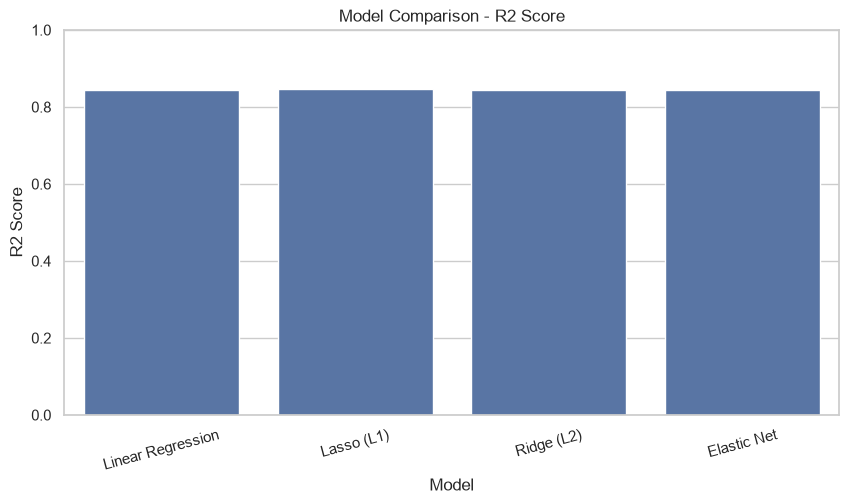

In [351]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title('Model Comparison - R2 Score')
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

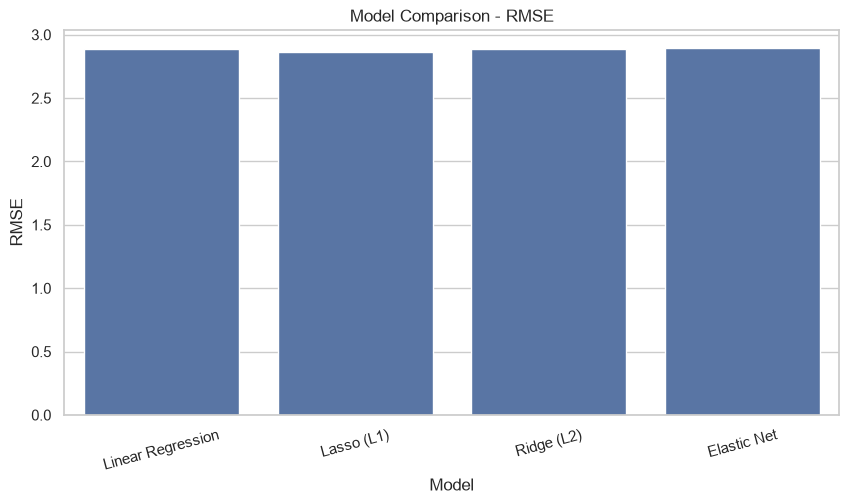

In [352]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('Model Comparison - RMSE')
plt.xticks(rotation=15)
plt.show()

In [353]:
coef_df = pd.DataFrame({
    name: model.coef_
    for name, model in trained_models.items()
}, index=X.columns)

coef_df

,Linear Regression,Lasso (L1),Ridge (L2),Elastic Net
cylinders,-0.278695,-0.000000,-0.253602,-0.180748
displacement,2.033373,-0.000000,1.894963,-0.000000
horsepower,-0.539182,-0.116899,-0.560929,-0.772397
weight,-5.914735,-4.730908,-5.800426,-3.969143
acceleration,0.187514,0.000000,0.164661,-0.011816
model_year,2.971431,2.493242,2.957105,2.631736
origin_1,-0.772028,-0.727874,-0.765575,-0.918388
origin_2,0.517752,0.000000,0.509899,0.145476
origin_3,0.439408,0.000000,0.439047,0.215011


In [354]:
coef_comparison = pd.DataFrame({
    'Feature': X.columns,
    'Baseline': trained_models['Linear Regression'].coef_,
    'Lasso (L1)': trained_models['Lasso (L1)'].coef_,
    'Ridge (L2)': trained_models['Ridge (L2)'].coef_
})

coef_comparison

,Feature,Baseline,Lasso (L1),Ridge (L2)
0,cylinders,-0.278695,-0.000000,-0.253602
1,displacement,2.033373,-0.000000,1.894963
2,horsepower,-0.539182,-0.116899,-0.560929
3,weight,-5.914735,-4.730908,-5.800426
4,acceleration,0.187514,0.000000,0.164661
5,model_year,2.971431,2.493242,2.957105
6,origin_1,-0.772028,-0.727874,-0.765575
7,origin_2,0.517752,0.000000,0.509899
8,origin_3,0.439408,0.000000,0.439047


In [355]:
coef_comparison['Lasso Change'] = (
    coef_comparison['Lasso (L1)'] -
    coef_comparison['Baseline']
)

coef_comparison['Ridge Change'] = (
    coef_comparison['Ridge (L2)'] -
    coef_comparison['Baseline']
)

coef_comparison

,Feature,Baseline,Lasso (L1),Ridge (L2),Lasso Change,Ridge Change
0,cylinders,-0.278695,-0.000000,-0.253602,0.278695,0.025094
1,displacement,2.033373,-0.000000,1.894963,-2.033373,-0.138411
2,horsepower,-0.539182,-0.116899,-0.560929,0.422283,-0.021747
3,weight,-5.914735,-4.730908,-5.800426,1.183828,0.114309
4,acceleration,0.187514,0.000000,0.164661,-0.187514,-0.022853
5,model_year,2.971431,2.493242,2.957105,-0.478189,-0.014325
6,origin_1,-0.772028,-0.727874,-0.765575,0.044154,0.006453
7,origin_2,0.517752,0.000000,0.509899,-0.517752,-0.007853
8,origin_3,0.439408,0.000000,0.439047,-0.439408,-0.000361


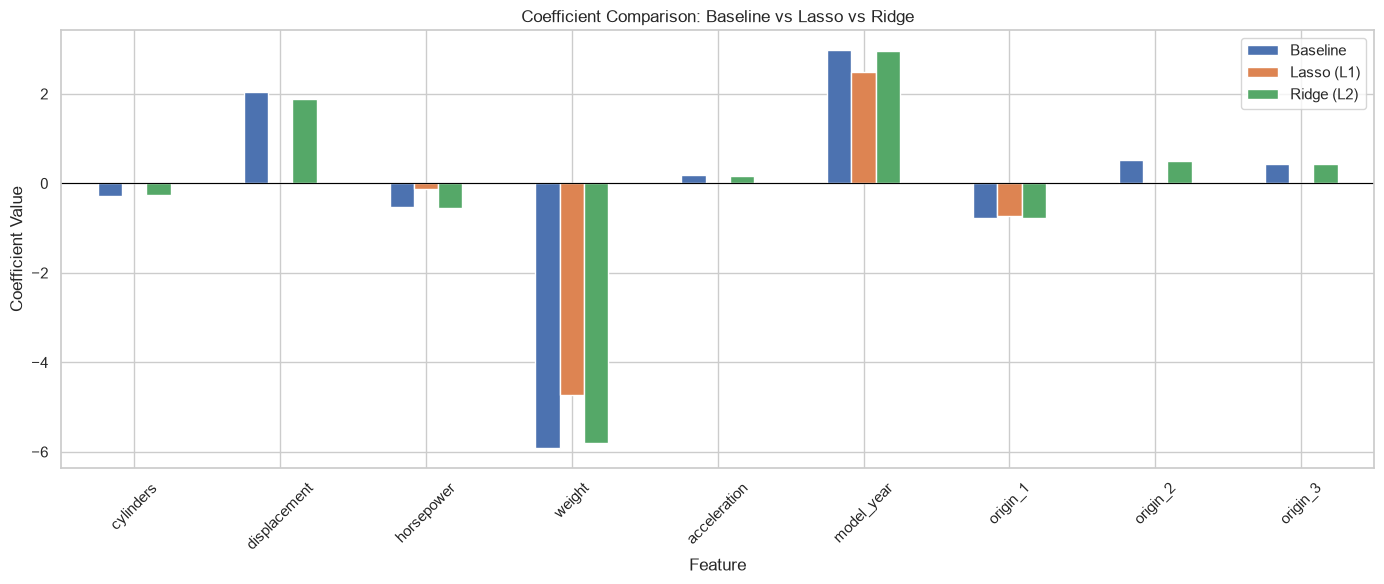

In [356]:
coef_comparison.set_index('Feature')[
    ['Baseline', 'Lasso (L1)', 'Ridge (L2)']
].plot(
    kind='bar',
    figsize=(14, 6)
)

plt.axhline(y=0, color='black', linewidth=0.8)
plt.title('Coefficient Comparison: Baseline vs Lasso vs Ridge')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Setelah dilakukan uji coba mengubah nilai alpha menjadi 0.5 untuk L1, L2 dan Elastic. Dihasilkan bahwa model dengan regularization Lasso (L1) menghasilkan R2 terbaik di angka 84,76%. Ditelaah lebih lanjut bahwa koefisien dari fitur-fitur seperti cylinders, displacement, acceleration, origin_2 dan origin_3 dihilangkan  dan fitur horsepower, weight, model_year dan origin_1 juga diperkecil koefisiennya.